<a href="https://colab.research.google.com/github/oliviadellaglio/ds2002-walmart-midterm/blob/main/2026_10_30_%E2%80%94_Midterm_Progress_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import time
import os

landfall = pd.Timestamp("2024-09-26")

In [20]:
import subprocess
from pathlib import Path

repo_path = Path("/content/ds2002-walmart-midterm")

if not repo_path.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/oliviadellaglio/ds2002-walmart-midterm.git",
            str(repo_path)
        ],
        check=True
    )

df = pd.read_csv(
    repo_path / "data" / "walmart_transactions.csv"
)

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

display(df.head())

Number of rows: 25562
Number of columns: 8


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-13T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-02 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-06 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-30 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-15 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


In [21]:
def clean_transactions(df):
    clean_df = df.copy()

    print("Original rows:", len(clean_df))

    clean_df = clean_df.drop_duplicates()
    print("After removing duplicates:", len(clean_df))

    clean_df["unit_price"] = pd.to_numeric(
        clean_df["unit_price"].astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    clean_df["quantity"] = pd.to_numeric(
        clean_df["quantity"], errors="coerce"
    )

    clean_df = clean_df[clean_df["quantity"] > 0]
    print("After removing invalid quantities:", len(clean_df))

    clean_df["timestamp"] = pd.to_datetime(
        clean_df["timestamp"],
        format="mixed",
        errors="coerce"
    )

    clean_df = clean_df.dropna(subset=["timestamp"])
    print("After removing missing timestamps:", len(clean_df))

    clean_df["store_id"] = (
    clean_df["store_id"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("_", "-", regex=False)
    .str.replace(r"^FL(?=\d{3}$)", "FL-", regex=True)
    )

    for col in ["category", "sku"]:
        if col in clean_df.columns:
            clean_df[col] = (
                clean_df[col]
                .astype(str)
                .str.strip()
                .str.upper()
            )

    print("Final cleaned rows:", len(clean_df))
    print("Total rows removed:", len(df) - len(clean_df))

    return clean_df


clean_df = clean_transactions(df)

display(clean_df.head())

Original rows: 25562
After removing duplicates: 25532
After removing invalid quantities: 25402
After removing missing timestamps: 24521
Final cleaned rows: 24521
Total rows removed: 1041


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-13 09:48:13,PNUTBTR-16,PEANUT BUTTER,GROCERY,1,3.15
1,TXN000759,FL-412,2024-09-02 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-06 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,HOUSEHOLD ESSENTIALS,2,10.47
3,TXN025020,FL-330,2024-09-30 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-15 15:59:42,BEER-24,Light Beer 24pk,ALCOHOLIC BEVERAGES,3,18.82


In [22]:
catalog = pd.read_csv(
    repo_path / "data" / "product_catalog.csv"
)

catalog["sku"] = catalog["sku"].astype(str).str.strip().str.upper()

product_groups = {
    "STRAWBERRY_POP_TARTS": [
        "PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"
    ],
    "BOTTLED_WATER": [
        "WTR-24", "WATER24PK", "WTR_24PK"
    ],
    "AA_BATTERIES": [
        "BATT-100", "BAT-AA4", "BATT_AA_4PK"
    ],
    "LED_FLASHLIGHT": [
        "FLASH-01", "LED-FLASH"
    ],
    "LIGHT_BEER": [
        "BEER-24", "LTBEER24"
    ],
    "MONOPOLY": [
        "BG-MONO", "MONOPOLY-01", "GAME-MONO"
    ],
    "PLAYING_CARDS": [
        "CARDS-01", "PLAYCARD-STD"
    ],
    "STREAMING_DEVICE": [
        "STREAM-01", "ROKU-STD"
    ],
    "CANNED_SOUP": [
        "SOUP-CAN", "CNSOUP-01"
    ],
    "WHITE_BREAD": [
        "BREAD-WH", "WHITEBREAD"
    ],
    "PEANUT_BUTTER": [
        "PB-16", "PNUTBTR-16"
    ],
    "EMERGENCY_CANDLES": [
        "CNDL-EM", "CANDLE-EMRG"
    ],
    "FIRST_AID_KIT": [
        "FAID-01", "FIRSTAID-KIT"
    ],
    "PORTABLE_CHARGER": [
        "CHRG-PORT", "PORTCHARGER"
    ],
    "VARIETY_CHIPS": [
        "CHIPS-VP", "CHIPVARIETY"
    ],
    "PAPER_TOWELS": [
        "PTOWEL-6", "PAPERTOWEL6"
    ],
    "TOILET_PAPER": [
        "TP-12", "TOILETPAPER12"
    ],
    "SIZE_3_DIAPERS": [
        "DIAP-S3", "DIAPERS-3"
    ],
    "BABY_FORMULA": [
        "BFORM-01", "BABYFORMULA"
    ],
    "HEAVY_DUTY_TARP": [
        "TARP-HD", "HDTARP-01"
    ]
}

sku_mapping = pd.DataFrame(
    [
        {"sku": sku, "canonical_product": product}
        for product, sku_list in product_groups.items()
        for sku in sku_list
    ]
)

assert sku_mapping["sku"].is_unique

unmapped_catalog = catalog.loc[
    ~catalog["sku"].isin(sku_mapping["sku"])
]

print("Unmapped catalog SKUs:", len(unmapped_catalog))
display(unmapped_catalog)

assert unmapped_catalog.empty, "Some catalog SKUs are not mapped"

clean_df = clean_transactions(df)

rows_before = len(clean_df)
units_before = clean_df["quantity"].sum()

clean_df = clean_df.merge(
    sku_mapping,
    on="sku",
    how="left",
    validate="many_to_one"
)

unmapped_transactions = clean_df.loc[
    clean_df["canonical_product"].isna(),
    ["sku", "product_name"]
].drop_duplicates()

print("Unmapped transaction SKUs:", len(unmapped_transactions))
display(unmapped_transactions)

assert unmapped_transactions.empty, "Some transaction SKUs are not mapped"

assert len(clean_df) == rows_before
assert clean_df["quantity"].sum() == units_before

print("Original SKUs:", df["sku"].nunique())
print("Canonical products:", clean_df["canonical_product"].nunique())
print("Rows preserved:", len(clean_df))
print("Total units preserved:", units_before)

display(sku_mapping.sort_values("canonical_product"))

Unmapped catalog SKUs: 0


,sku,product_name,category,subcategory,unit_cost,supplier,package_size


Original rows: 25562
After removing duplicates: 25532
After removing invalid quantities: 25402
After removing missing timestamps: 24521
Final cleaned rows: 24521
Total rows removed: 1041
Unmapped transaction SKUs: 0


,sku,product_name


Original SKUs: 45
Canonical products: 20
Rows preserved: 24521
Total units preserved: 47897


,sku,canonical_product
7,BATT-100,AA_BATTERIES
8,BAT-AA4,AA_BATTERIES
9,BATT_AA_4PK,AA_BATTERIES
42,BABYFORMULA,BABY_FORMULA
41,BFORM-01,BABY_FORMULA
4,WTR-24,BOTTLED_WATER
5,WATER24PK,BOTTLED_WATER
6,WTR_24PK,BOTTLED_WATER
22,CNSOUP-01,CANNED_SOUP
21,SOUP-CAN,CANNED_SOUP


In [23]:
category_mapping = {
    "ALCOHOLIC BEVERAGES": "ALCOHOL",
    "BABY PRODUCTS": "BABY",
    "BREAKFAST FOODS": "BREAKFAST",
    "EMERGENCY SUPPLIES": "EMERGENCY",
    "GAMES & ENTERTAINMENT": "ENTERTAINMENT",
    "GROCERIES": "GROCERY",
    "HEALTH & WELLNESS": "HEALTH",
    "HOUSEHOLD ESSENTIALS": "HOUSEHOLD"
}

rows_before = len(clean_df)
units_before = clean_df["quantity"].sum()

clean_df["category"] = clean_df["category"].replace(category_mapping)

assert len(clean_df) == rows_before
assert clean_df["quantity"].sum() == units_before

print("Categories after standardization:")
print(sorted(clean_df["category"].unique()))
print("Number of categories:", clean_df["category"].nunique())

Categories after standardization:
['ALCOHOL', 'BABY', 'BREAKFAST', 'ELECTRONICS', 'EMERGENCY', 'ENTERTAINMENT', 'GROCERY', 'HEALTH', 'HOUSEHOLD', 'SNACKS']
Number of categories: 10


In [24]:
print("Cleaned transactions:", len(clean_df))
print("Canonical products:", clean_df["canonical_product"].nunique())

assert len(clean_df) == 24521
assert clean_df["canonical_product"].nunique() == 20

Cleaned transactions: 24521
Canonical products: 20


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [25]:
landfall = pd.Timestamp("2024-09-26")
baseline_start = pd.Timestamp("2024-09-01")
baseline_end = pd.Timestamp("2024-09-08")
surge_start = pd.Timestamp("2024-09-19")
surge_end = pd.Timestamp("2024-09-25")

q1_sales = clean_df.copy()
q1_sales["date"] = pd.to_datetime(q1_sales["timestamp"]).dt.normalize()

daily_products = (
    q1_sales.groupby(["date", "canonical_product"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(pd.date_range("2024-09-01", "2024-09-30"), fill_value=0)
)

baseline_avg = daily_products.loc[baseline_start:baseline_end].mean()
surge_avg = daily_products.loc[surge_start:surge_end].mean()

q1_table = pd.DataFrame({
    "Baseline Avg Units/Day": baseline_avg,
    "Surge Avg Units/Day": surge_avg
})

q1_table["Surge Multiple"] = (
    q1_table["Surge Avg Units/Day"]
    / q1_table["Baseline Avg Units/Day"].replace(0, np.nan)
)

q1_table["Percentage Change"] = (
    (q1_table["Surge Multiple"] - 1) * 100
)

print("Baseline: September 1–8, 2024")
print("Surge window: September 19–25, 2024")
print("Landfall: September 26, 2024")

display(q1_table.sort_values("Surge Multiple", ascending=False).round(2))

total_baseline = baseline_avg.sum()
total_surge = surge_avg.sum()

print(f"\nBaseline total: {total_baseline:.2f} units/day")
print(f"Pre-landfall total: {total_surge:.2f} units/day")
print(f"Overall multiple: {total_surge / total_baseline:.2f}x")

Baseline: September 1–8, 2024
Surge window: September 19–25, 2024
Landfall: September 26, 2024


,Baseline Avg Units/Day,Surge Avg Units/Day,Surge Multiple,Percentage Change
canonical_product,,,,
SIZE_3_DIAPERS,43.00,43.00,1.00,0.00
VARIETY_CHIPS,58.00,57.00,0.98,-1.72
BOTTLED_WATER,122.88,120.71,0.98,-1.76
WHITE_BREAD,66.12,60.57,0.92,-8.40
PORTABLE_CHARGER,48.50,44.14,0.91,-8.98
LIGHT_BEER,67.88,61.29,0.90,-9.71
FIRST_AID_KIT,49.25,44.43,0.90,-9.79
PEANUT_BUTTER,49.38,44.00,0.89,-10.89
MONOPOLY,47.88,42.29,0.88,-11.67



Baseline total: 1307.38 units/day
Pre-landfall total: 1107.43 units/day
Overall multiple: 0.85x


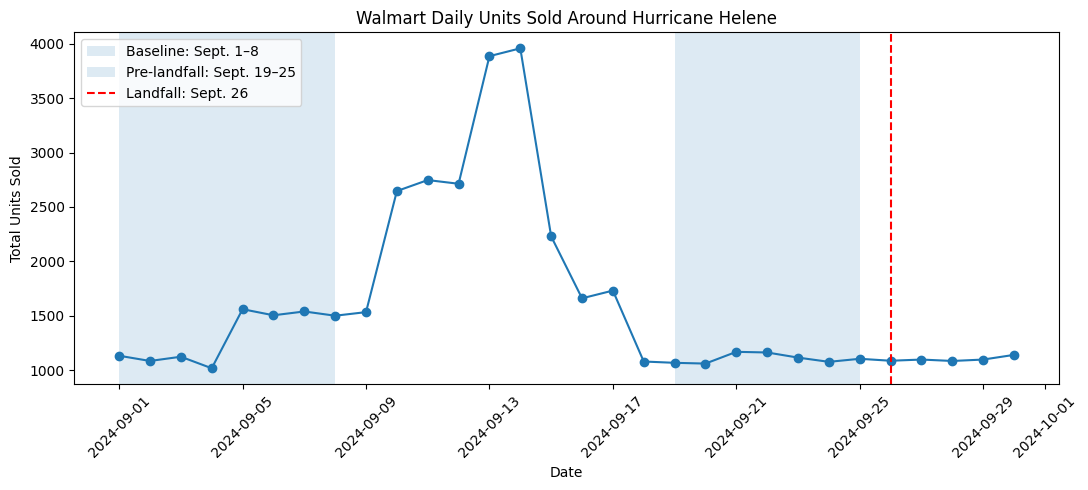

In [26]:
import matplotlib.pyplot as plt

total_daily = daily_products.sum(axis=1)

plt.figure(figsize=(11, 5))

plt.plot(total_daily.index, total_daily.values, marker="o")

plt.axvspan(
    baseline_start, baseline_end,
    alpha=0.15, label="Baseline: Sept. 1–8"
)

plt.axvspan(
    surge_start, surge_end,
    alpha=0.15, label="Pre-landfall: Sept. 19–25"
)

plt.axvline(
    landfall, color="red", linestyle="--",
    label="Landfall: Sept. 26"
)

plt.title("Walmart Daily Units Sold Around Hurricane Helene")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

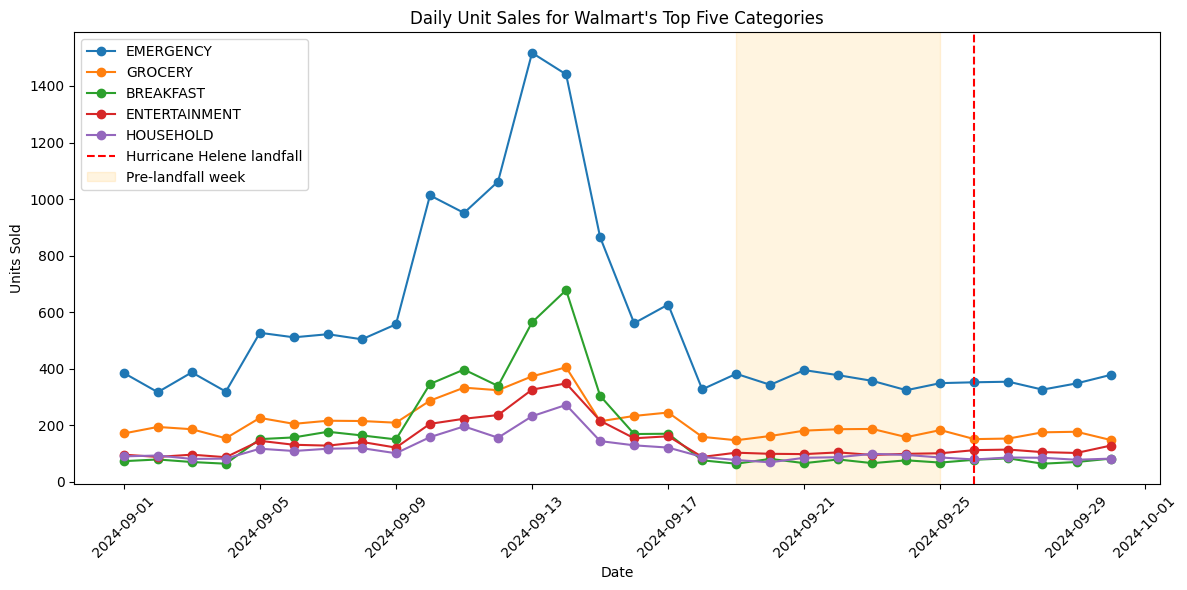

Top five categories:
['EMERGENCY', 'GROCERY', 'BREAKFAST', 'ENTERTAINMENT', 'HOUSEHOLD']


In [27]:
q1_categories = clean_df.copy()

q1_categories["date"] = pd.to_datetime(
    q1_categories["timestamp"],
    errors="coerce"
).dt.normalize()

top5 = (
    q1_categories.groupby("category")["quantity"]
    .sum()
    .nlargest(5)
    .index
)

daily_categories = (
    q1_categories[
        q1_categories["category"].isin(top5)
    ]
    .groupby(["date", "category"])["quantity"]
    .sum()
    .unstack(fill_value=0)
)

dates = pd.date_range("2024-09-01", "2024-09-30")
daily_categories = daily_categories.reindex(
    dates, fill_value=0
)

plt.figure(figsize=(12, 6))

for category in top5:
    plt.plot(
        daily_categories.index,
        daily_categories[category],
        marker="o",
        label=category
    )

plt.axvline(
    pd.Timestamp("2024-09-26"),
    color="red",
    linestyle="--",
    label="Hurricane Helene landfall"
)

plt.axvspan(
    pd.Timestamp("2024-09-19"),
    pd.Timestamp("2024-09-25"),
    color="orange",
    alpha=0.12,
    label="Pre-landfall week"
)

plt.title("Daily Unit Sales for Walmart's Top Five Categories")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print("Top five categories:")
print(list(top5))

In [28]:
display(
    clean_df.groupby(["category", "canonical_product"])
    ["quantity"].sum().to_frame("Units Sold")
)

Units Sold
category      canonical_product               
ALCOHOL       LIGHT_BEER                  2493
BABY          BABY_FORMULA                1522
              SIZE_3_DIAPERS              1473
BREAKFAST     STRAWBERRY_POP_TARTS        5005
ELECTRONICS   PORTABLE_CHARGER            1888
              STREAMING_DEVICE            1159
EMERGENCY     AA_BATTERIES                4154
              BOTTLED_WATER               5037
              EMERGENCY_CANDLES           2546
              HEAVY_DUTY_TARP             2127
              LED_FLASHLIGHT              2814
ENTERTAINMENT MONOPOLY                    1938
              PLAYING_CARDS               2312
GROCERY       CANNED_SOUP                 2538
              PEANUT_BUTTER               1580
              WHITE_BREAD                 2239
HEALTH        FIRST_AID_KIT               1783
HOUSEHOLD     PAPER_TOWELS                1725
              TOILET_PAPER                1688
SNACKS        VARIETY_CHIPS               1876

In [29]:
category_check = (
    clean_df.groupby("category")["canonical_product"]
    .unique()
    .reset_index()
)

display(category_check)

,category,canonical_product
0,ALCOHOL,[LIGHT_BEER]
1,BABY,"[BABY_FORMULA, SIZE_3_DIAPERS]"
2,BREAKFAST,[STRAWBERRY_POP_TARTS]
3,ELECTRONICS,"[STREAMING_DEVICE, PORTABLE_CHARGER]"
4,EMERGENCY,"[HEAVY_DUTY_TARP, EMERGENCY_CANDLES, LED_FLASH..."
5,ENTERTAINMENT,"[PLAYING_CARDS, MONOPOLY]"
6,GROCERY,"[PEANUT_BUTTER, CANNED_SOUP, WHITE_BREAD]"
7,HEALTH,[FIRST_AID_KIT]
8,HOUSEHOLD,"[TOILET_PAPER, PAPER_TOWELS]"
9,SNACKS,[VARIETY_CHIPS]


**Q1 answer, in one sentence a manager could read:**
We used September 1–8 as the normal-demand baseline and September 19–25 as the pre-landfall period, and we found that average daily Walmart unit sales decreased from 1,307.38 to 1,107.43 units, so it did not demonstrate an overall pre-landfall surge across the stores included in the data.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Original SKUs: 45
Canonical products: 20
Largest consolidated family: STRAWBERRY_POP_TARTS
Number of SKUs in family: 4

Before consolidation:


,Units Sold
sku,
POPTART-STRAW,1239
PT-12,1332
PT_STRAWBERRY,1230
SKU#459812,1204



After consolidation:
STRAWBERRY_POP_TARTS: 5005 units

Validation passed: total units preserved.


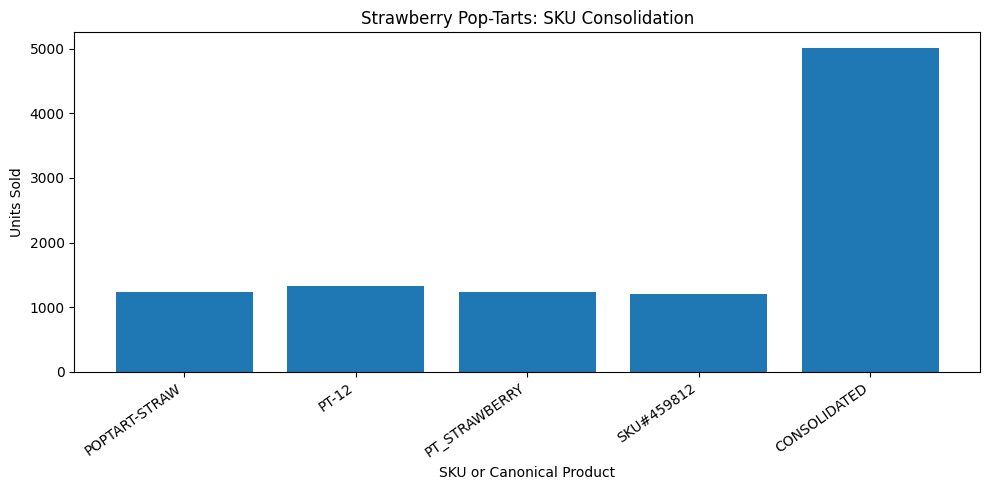

In [30]:
original_skus = clean_df["sku"].nunique()
canonical_products = clean_df["canonical_product"].nunique()

family_sizes = (
    clean_df.groupby("canonical_product")["sku"]
    .nunique()
    .sort_values(ascending=False)
)

largest_family = family_sizes.index[0]
largest_family_size = family_sizes.iloc[0]

poptarts = clean_df[
    clean_df["canonical_product"] == "STRAWBERRY_POP_TARTS"
]

before = poptarts.groupby("sku")["quantity"].sum()
after = poptarts["quantity"].sum()

print("Original SKUs:", original_skus)
print("Canonical products:", canonical_products)
print("Largest consolidated family:", largest_family)
print("Number of SKUs in family:", largest_family_size)

print("\nBefore consolidation:")
display(before.to_frame("Units Sold"))

print("\nAfter consolidation:")
print("STRAWBERRY_POP_TARTS:", after, "units")

assert before.sum() == after

assert (
    clean_df.groupby("sku")["quantity"].sum().sum()
    == clean_df.groupby("canonical_product")["quantity"].sum().sum()
)

print("\nValidation passed: total units preserved.")

labels = list(before.index) + ["CONSOLIDATED"]
values = list(before.values) + [after]

plt.figure(figsize=(10, 5))
plt.bar(labels, values)
plt.title("Strawberry Pop-Tarts: SKU Consolidation")
plt.xlabel("SKU or Canonical Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Q2 answer:**

We consolidated 45 original SKUs into 20 canonical products, and Strawberry Pop-Tarts were one of the largest consolidated groups. It had four SKUs and 5,005 total units sold, and validation confirmed that consolidation preserved total sales quantities.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [31]:
BASE = "https://archive-api.open-meteo.com/v1/archive"

RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(
    start,
    end,
    lat=30.4383,
    lon=-84.2807,
    tries=3
):
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": (
            "wind_gusts_10m_max,"
            "wind_speed_10m_max,"
            "precipitation_sum,"
            "pressure_msl_mean"
        ),
        "timezone": "America/New_York"
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(
                BASE,
                params=params,
                timeout=20
            )

            if r.status_code in RETRY_STATUSES:
                r.raise_for_status()

            r.raise_for_status()

            weather = pd.DataFrame(r.json()["daily"])

            weather = weather.rename(
                columns={"time": "date"}
            )

            weather["date"] = pd.to_datetime(
                weather["date"]
            )

            weather["source"] = "open-meteo"

            return weather

        except requests.RequestException:
            if attempt == tries:
                raise

            time.sleep(2 ** attempt)

In [32]:
try:
    weather = daily_weather(
        "2024-09-01",
        "2024-09-30"
    )

    print("Weather API call successful!")
    print("Source:", weather["source"].iloc[0])
    print("Number of days:", len(weather))

    display(weather.head())

except requests.RequestException as err:
    print("Weather API call failed:", err)
    raise

Weather API call successful!
Source: open-meteo
Number of days: 30


,date,wind_gusts_10m_max,wind_speed_10m_max,precipitation_sum,pressure_msl_mean,source
0,2024-09-01,25.9,9.4,0.0,1014.0,open-meteo
1,2024-09-02,28.8,12.0,0.0,1013.3,open-meteo
2,2024-09-03,41.8,18.7,3.3,1015.8,open-meteo
3,2024-09-04,47.9,21.3,0.0,1018.9,open-meteo
4,2024-09-05,42.8,19.2,0.3,1017.7,open-meteo


Store sales days before join: 30
Days after join: 30
Matched days: 30
Weather source: ['open-meteo']
Days available for correlation: 30
Weather correlations with daily units sold:


,Pearson Correlation
wind_speed_10m_max,-0.026468
wind_gusts_10m_max,-0.033420
precipitation_sum,0.043086
pressure_msl_mean,0.150237


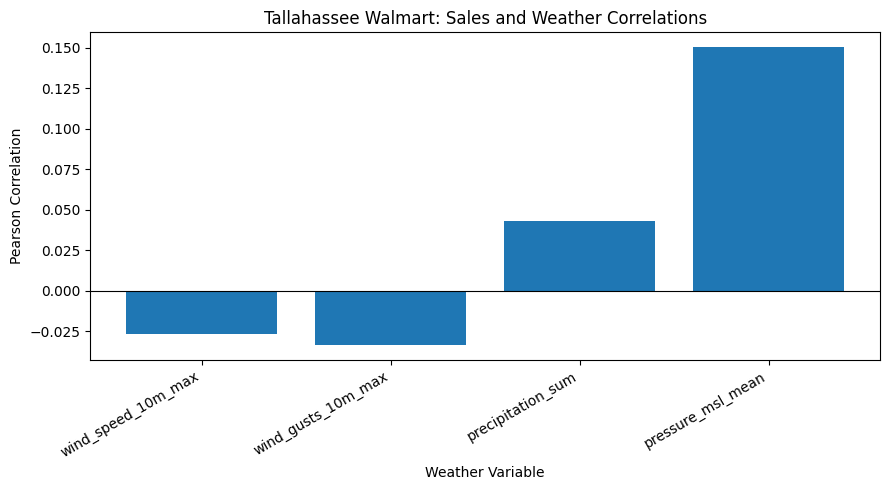

In [33]:
# Tallahassee store
store_id = "FL-619"

store_sales = clean_df[
    clean_df["store_id"] == store_id
].copy()

store_sales["date"] = (
    pd.to_datetime(store_sales["timestamp"]).dt.normalize()
)

daily_store_sales = (
    store_sales.groupby("date")["quantity"]
    .sum()
    .rename("units_sold")
    .reset_index()
)

q3_data = daily_store_sales.merge(
    weather,
    on="date",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Store sales days before join:", len(daily_store_sales))
print("Days after join:", len(q3_data))
print("Matched days:", (q3_data["_merge"] == "both").sum())

assert len(q3_data) == len(daily_store_sales), (
    "The join changed the number of sales days"
)

print("Weather source:", weather["source"].unique())

weather_columns = [
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "precipitation_sum",
    "pressure_msl_mean"
]

q3_complete = q3_data.dropna(
    subset=["units_sold"] + weather_columns
)

print("Days available for correlation:", len(q3_complete))

weather_columns = [
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "precipitation_sum",
    "pressure_msl_mean"
]

correlations = (
    q3_complete[["units_sold"] + weather_columns]
    .corr()["units_sold"]
    .drop("units_sold")
)

print("Weather correlations with daily units sold:")
display(correlations.to_frame("Pearson Correlation"))

plt.figure(figsize=(9, 5))
plt.bar(correlations.index, correlations.values)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Tallahassee Walmart: Sales and Weather Correlations")
plt.xlabel("Weather Variable")
plt.ylabel("Pearson Correlation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

,Weather Variable,Lag (days),Pearson Correlation,Days Used
0,wind_speed_10m_max,0,-0.026,30
1,wind_speed_10m_max,1,0.055,29
2,wind_speed_10m_max,2,0.072,28
3,wind_gusts_10m_max,0,-0.033,30
4,wind_gusts_10m_max,1,0.010,29
5,wind_gusts_10m_max,2,0.012,28
6,precipitation_sum,0,0.043,30
7,precipitation_sum,1,-0.025,29
8,precipitation_sum,2,-0.065,28
9,pressure_msl_mean,0,0.150,30


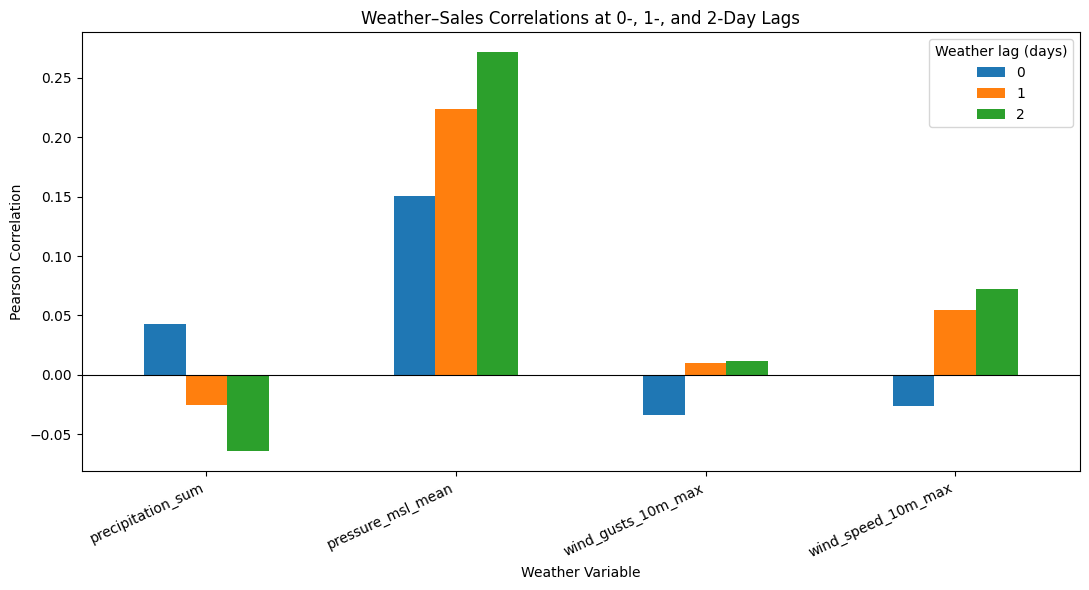

In [34]:
lag_data = q3_complete.copy().sort_values("date")

lag_data = lag_data.set_index("date").asfreq("D")

weather_variables = [
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "precipitation_sum",
    "pressure_msl_mean"
]

results = []

for variable in weather_variables:
    for lag in [0, 1, 2]:

        earlier_weather = lag_data[variable].shift(lag)

        paired = pd.DataFrame({
            "sales": lag_data["units_sold"],
            "weather": earlier_weather
        }).dropna()

        correlation = paired["sales"].corr(paired["weather"])

        results.append({
            "Weather Variable": variable,
            "Lag (days)": lag,
            "Pearson Correlation": correlation,
            "Days Used": len(paired)
        })

lag_results = pd.DataFrame(results)

display(lag_results.round(3))

lag_chart = lag_results.pivot(
    index="Weather Variable",
    columns="Lag (days)",
    values="Pearson Correlation"
)

lag_chart.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Weather–Sales Correlations at 0-, 1-, and 2-Day Lags")
plt.xlabel("Weather Variable")
plt.ylabel("Pearson Correlation")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Weather lag (days)")
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:**

We studied the sales at the Tallahassee Walmart for 30 days and historical weather data from the Open-Meteo API, and we did not find a strong correlation between daily unit sales and maximum wind speed (r = −0.026), wind gusts (r = −0.033), precipitation (r = 0.043), and mean sea-level pressure (r = 0.150). The validated join preserved the 30 daily sales records, and it did not have any unmatched dates. Therefore, there is not a strong linear relationship during this period. However, the sample only has data from 30 days at one store, and correlation does not establish causation. We also looked at weather conditions 1-2 days before to see if they were associated with daily sales. This lag analysis helped us compare same-day relationships with delayed relationships. It used 30 observations for the same-day comparisons, 29 for one-day lags, and 28 for two-day lags.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):**

We cleaned and validated the store-location data and matched the 24,521 transactions to their stores. Next, we are going to compare the changes in demand across the stores to see if geographic location influenced purchasing patterns. Emma will finish this analysis before our presentation.

**Q5 (signal or artifact):**

We finished the SKU and category cleaning for the inventory analysis, but we still need to query the SQLite inventory database and compare the records with our cleaned transaction data. The comparison we make will help us decide if the observed patterns are reflecting a meaningful demand or potential data artifacts. Then, we will develop a recommendation based on our findings. Liv will complete this analysis before our presentation.

### Self-check

In [36]:
progress = {
    'q1_multiple': round(total_surge / total_baseline, 2),
    'q1_baseline_window': '2024-09-01 to 2024-09-08',
    'q2_canonical_products': canonical_products,
    'q3_join_rows_preserved': (
        len(q3_data) == len(daily_store_sales)
        and (q3_data["_merge"] == "both").all()
    ),
    'q3_days_in_correlation': len(q3_complete),
    'charts_with_message_titles': 5,
    'notebook_runs_clean': True,
    'repo_pushed': True,
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 0.85
PASS - q1_baseline_window = 2024-09-01 to 2024-09-08
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 5
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a.) When we were working through the assignment, we were surprised that the data did not show an overall demand surge in the week before Hurricane Helene's landfall. At first, we used September 1–18 as the baseline, but we noticed that there was a substantial sales spike around September 12–13 that made the comparison questionable. Therefore, we looked at the daily sales throughout September and decided to change the baseline to September 1–8 because it was a more stable period. However, even after changing the baseline, the average daily sales decreased from 1,307.38 to 1,107.43 units.

b.) The number we reported that I am the least confident in is our overall demand multiple of 0.85× because it is dependent on the baseline period. September 1–8 appears relatively stable compared to 1-18, but it is only eight days of observations. I am also concerned that the calculation combines sales from all 12 stores because it could be misrepresenting the changes in purchasing behavior from the hurricane from the different locations.